In [1]:
%pip install numpy matplotlib nbconvert scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Is the Kalman Filter Just a Low-Pass Filter?

A scalar Kalman filter for the **local-level / random-walk** signal

$$x_{k+1} = x_k + w_k,\quad w_k\sim\mathcal N(0,q^2)\qquad
  z_k = x_k + v_k,\quad v_k\sim\mathcal N(0,r^2)$$

converges to a **constant gain** $K_\mathrm{ss}$, and its update collapses to

$$\mu_k = (1-K_\mathrm{ss})\,\mu_{k-1} + K_\mathrm{ss}\,z_k$$

— *exactly* a first-order **low-pass** (exponential moving average) with pole $1-K_\mathrm{ss}$.
The complementary **high-pass** is $z-\mathrm{lowpass}(z)$, and in the stationary limit the whole
thing coincides with the frequency-domain **Wiener filter** $H=S_{xx}/(S_{xx}+S_{nn})$.

We build this with `kalman.apps.signals.ScalarSignalModel` (a one-state linear model) and the
app-level baselines `LowPassFilter`, `HighPassFilter`, `WienerFilter`, then quantify the gain with
**error-std ratios** and **Gaussian pull distributions**.
*(ref: thesearesystems — "Is the Kalman Filter Just a Low-Pass Filter?")*

## 1 — The model and its steady-state gain

Solving the scalar Riccati fixed point $P^-=P+Q,\ K=P^-/(P^-+R),\ P=(1-K)P^-$ gives the closed form

$$K_\mathrm{ss}=\frac{\sqrt{q^4+4q^2r^2}-q^2}{2r^2},\qquad \text{pole}=1-K_\mathrm{ss}.$$

The ratio $q/r$ is the only knob: large $q$ ⇒ trust the data ⇒ high cutoff; small $q$ ⇒ heavy smoothing.

In [2]:
from kalman.apps.signals import (
    ScalarSignalModel, LowPassFilter, HighPassFilter, WienerFilter, pull, error_ratio)

fs = 100.0
model = ScalarSignalModel("temp", fs=fs, measurement_uncertainty=1.0, process_uncertainty=0.05)
ss = model.steady_state_gain()
print(f"steady-state gain  K_ss = {ss.gain:.4f}")
print(f"prior variance  P^-     = {ss.prior_var:.4f}")
print(f"posterior var   P       = {ss.posterior_var:.4f}  (sigma = {ss.posterior_var**0.5:.3f})")
print(f"equivalent low-pass pole = {1-ss.gain:.4f}")
print(f"cutoff frequency  f_c    = {model.cutoff_frequency():.3f} Hz")

steady-state gain  K_ss = 0.0488
prior variance  P^-     = 0.0513
posterior var   P       = 0.0488  (sigma = 0.221)
equivalent low-pass pole = 0.9512
cutoff frequency  f_c    = 0.796 Hz


## 2 — A drifting signal, filtered

We draw a genuine random-walk realisation with `covariance=False` (the default sampling path keeps
the truth mean flat and only inflates $P_k$). The signature figure overlays the Kalman estimate
($\pm1\sigma$), the steady-state low-pass and the Wiener filter, plus the equivalent Bode response
and the pull distributions.

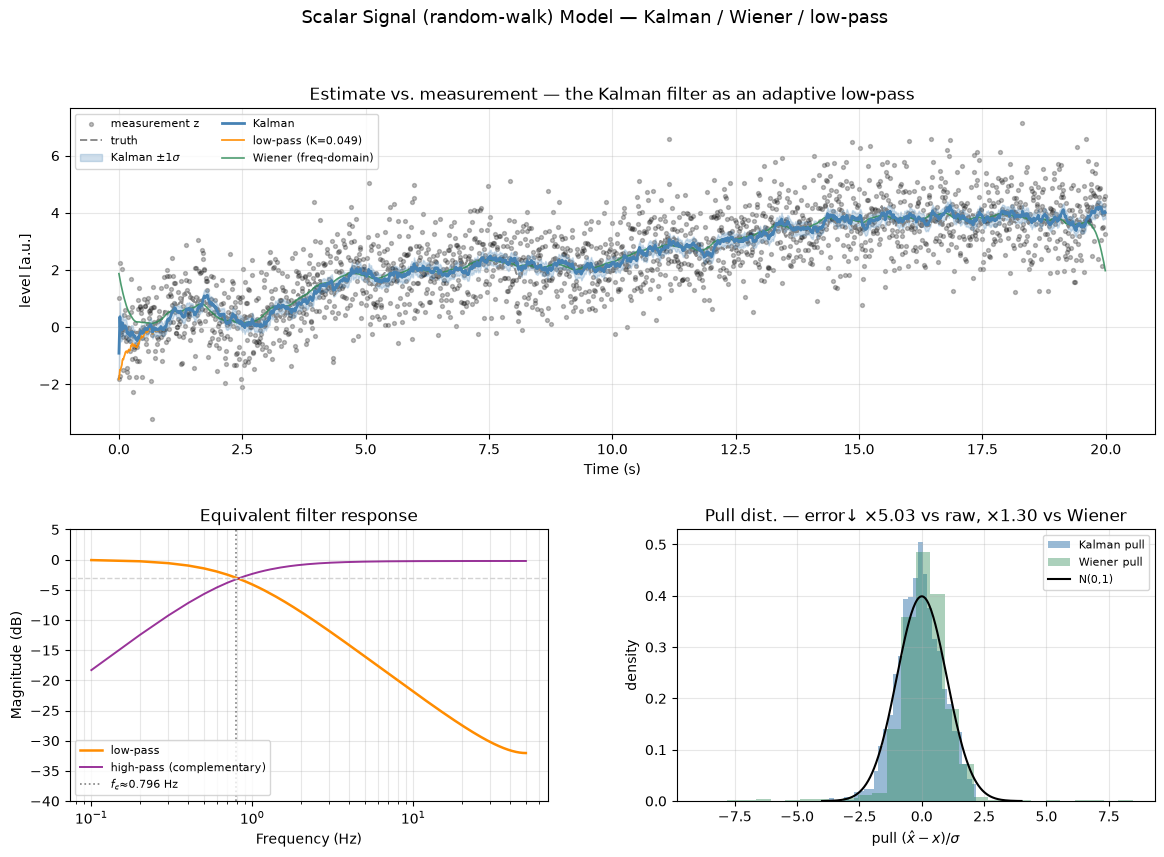

In [3]:
chrono.restart()
sample = model.sample(20.0, covariance=False)     # real random-walk truth + noisy measurements
record = model.filter(sample.zk)                   # forward (causal) Kalman
chrono.lap("sampled + filtered")

model.plot(record, sample=sample)
plt.show()

## 3 — The Kalman filter *is* the steady-state low-pass

Seed a one-pole low-pass with $\alpha=K_\mathrm{ss}$ (`LowPassFilter.from_model`). Once the Kalman
gain has converged the two outputs are indistinguishable.

max |Kalman - low-pass| in steady state: 5.77e-15


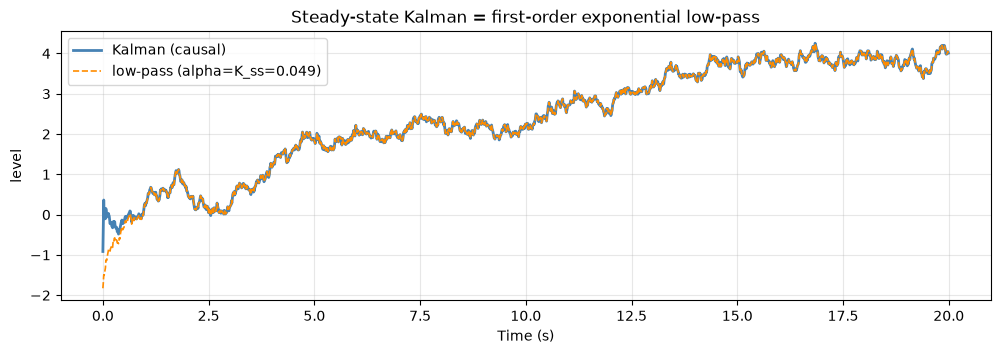

In [4]:
lp = LowPassFilter.from_model(model).apply(sample.zk)
xk = record.xk.ravel()
tail = slice(len(lp)//2, None)
print(f"max |Kalman - low-pass| in steady state: {np.max(np.abs(xk[tail]-lp[tail])):.2e}")

t = sample.time
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t, xk, color="steelblue", lw=2.0, label="Kalman (causal)")
ax.plot(t, lp, color="darkorange", lw=1.2, ls="--", label=f"low-pass (alpha=K_ss={ss.gain:.3f})")
ax.set_xlabel("Time (s)"); ax.set_ylabel("level"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Steady-state Kalman = first-order exponential low-pass")
plt.show()

## 4 — Complementary high-pass and the Bode view

The high-pass is simply $z-\mathrm{lowpass}(z)$, so $\mathrm{low}+\mathrm{high}=z$ identically.
On the Bode plot the low-pass passes the slow signal and the high-pass passes the fast noise; they
cross at the cutoff $f_c$.

max |low + high - z|: 4.44e-16  (perfect complement)


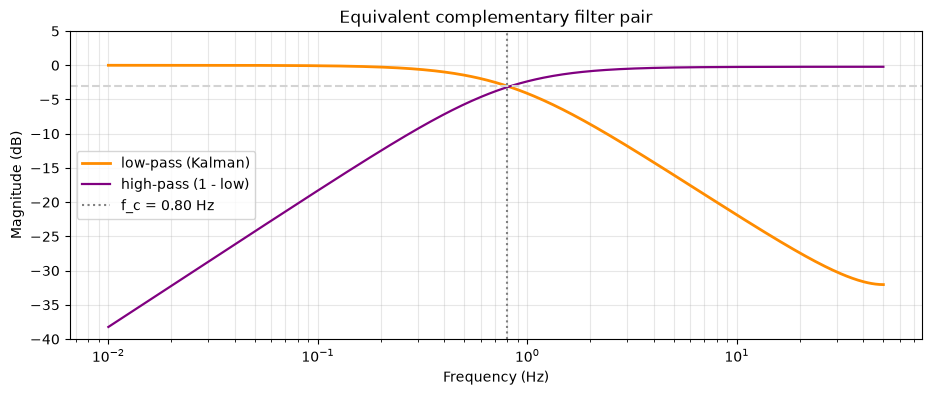

In [5]:
hp = HighPassFilter.from_model(model).apply(sample.zk)
print(f"max |low + high - z|: {np.max(np.abs(lp + hp - sample.zk.ravel())):.2e}  (perfect complement)")

freqs = np.logspace(-2, np.log10(fs/2), 400)
H = model.frequency_response(freqs)
fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogx(freqs, 20*np.log10(np.abs(H)), color="darkorange", lw=2, label="low-pass (Kalman)")
ax.semilogx(freqs, 20*np.log10(np.abs(1-H)+1e-12), color="purple", lw=1.6, label="high-pass (1 - low)")
ax.axvline(model.cutoff_frequency(), color="gray", ls=":", label=f"f_c = {model.cutoff_frequency():.2f} Hz")
ax.axhline(-3, color="lightgray", ls="--")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Magnitude (dB)"); ax.set_ylim(-40, 5)
ax.legend(); ax.grid(alpha=0.3, which="both"); ax.set_title("Equivalent complementary filter pair")
plt.show()

## 5 — Kalman → Wiener, and how much it actually helps

The stationary optimum is the **Wiener filter** $H(\omega)=S_{xx}/(S_{xx}+r^2)$ with
$S_{xx}(\omega)=q^2/(2-2\cos\omega)$ (so $H\to1$ at DC). We apply it as a zero-phase FFT smoother and
compare. The **error-std ratio** says how much smaller the residual is than the raw measurement.

In [6]:
wf = WienerFilter.from_model(model).apply(sample.zk)
truth = sample.xk.ravel()
burn = 300   # skip the start-up transient
r_raw    = error_ratio(sample.zk.ravel()[burn:]-truth[burn:], xk[burn:]-truth[burn:])
r_wiener = error_ratio(wf[burn:]-truth[burn:],                xk[burn:]-truth[burn:])
print(f"error-std ratio  raw / Kalman    = {r_raw:.2f}x   (Kalman {r_raw:.1f}x tighter than the sensor)")
print(f"error-std ratio  Wiener / Kalman = {r_wiener:.2f}x  (~1 => causal Kalman ~ stationary Wiener)")

error-std ratio  raw / Kalman    = 5.32x   (Kalman 5.3x tighter than the sensor)
error-std ratio  Wiener / Kalman = 1.21x  (~1 => causal Kalman ~ stationary Wiener)


## 6 — Gaussian pull distributions (is the uncertainty honest?)

The **pull** $(\hat x-x)/\sigma$ should be $\mathcal N(0,1)$ when the reported covariance is
consistent. We compute it for the Kalman filter (using its own $\sqrt{P_k}$) and for the Wiener
filter (using the steady-state posterior $\sigma$).

Kalman pull:  mean=+0.031  std=0.862
Wiener pull:  mean=+0.100  std=1.045   (both should be ~0 / ~1)


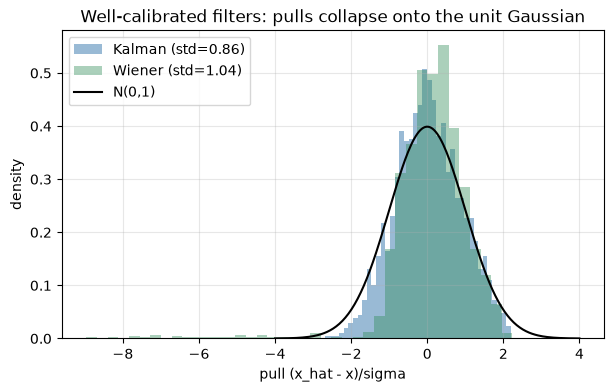

In [7]:
sig_k = np.sqrt(record.Pk[:, 0, 0])
pk = pull(xk[burn:], truth[burn:], sig_k[burn:])
pw = pull(wf[burn:], truth[burn:], np.sqrt(ss.posterior_var))
print(f"Kalman pull:  mean={pk.mean():+.3f}  std={pk.std():.3f}")
print(f"Wiener pull:  mean={pw.mean():+.3f}  std={pw.std():.3f}   (both should be ~0 / ~1)")

from scipy.stats import norm
gx = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(pk, bins=40, density=True, alpha=0.55, color="steelblue", label=f"Kalman (std={pk.std():.2f})")
ax.hist(pw, bins=40, density=True, alpha=0.40, color="seagreen", label=f"Wiener (std={pw.std():.2f})")
ax.plot(gx, norm.pdf(gx), "k", lw=1.5, label="N(0,1)")
ax.set_xlabel("pull (x_hat - x)/sigma"); ax.set_ylabel("density"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Well-calibrated filters: pulls collapse onto the unit Gaussian")
plt.show()

## 7 — The cutoff is set by $q/r$

Sweeping the process noise $q$ moves the cutoff and trades smoothing against responsiveness: small
$q$ ⇒ low cutoff ⇒ strong noise rejection (large error-ratio) but more lag.

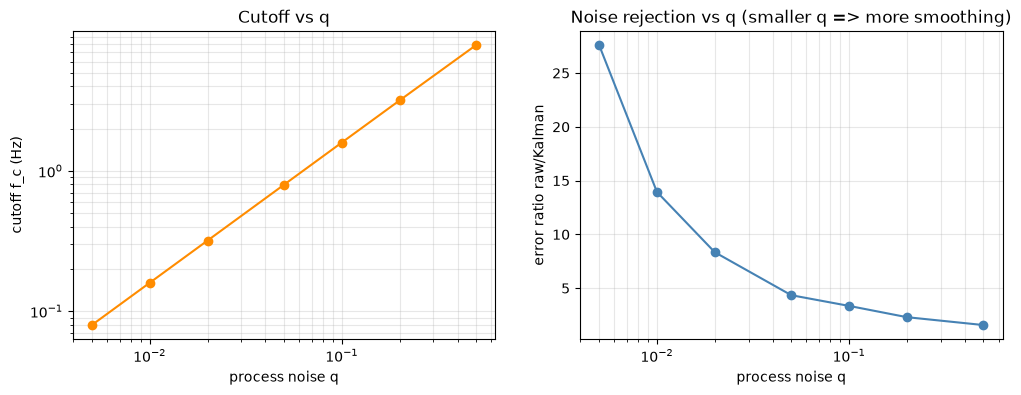

In [8]:
qs = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5])
fcs, ratios = [], []
for q in qs:
    mq = ScalarSignalModel("temp", fs=fs, measurement_uncertainty=1.0, process_uncertainty=q)
    s = mq.sample(20.0, covariance=False)
    rf = mq.filter(s.zk)
    fcs.append(mq.cutoff_frequency())
    tr = s.xk.ravel()
    ratios.append(error_ratio(s.zk.ravel()[burn:]-tr[burn:], rf.xk.ravel()[burn:]-tr[burn:]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(qs, fcs, "o-", color="darkorange"); ax[0].set_xlabel("process noise q"); ax[0].set_ylabel("cutoff f_c (Hz)")
ax[0].grid(alpha=0.3, which="both"); ax[0].set_title("Cutoff vs q")
ax[1].semilogx(qs, ratios, "o-", color="steelblue"); ax[1].set_xlabel("process noise q")
ax[1].set_ylabel("error ratio raw/Kalman"); ax[1].grid(alpha=0.3, which="both")
ax[1].set_title("Noise rejection vs q (smaller q => more smoothing)")
plt.show()

## Takeaways

- A steady-state scalar Kalman filter **is** a first-order low-pass; $K_\mathrm{ss}$ sets the cutoff.
- Its complement is a high-pass; together they partition the signal at $f_c$.
- It coincides with the **Wiener filter** in the stationary limit — but the Kalman form also handles
  the start-up transient and non-stationary $q,r$ automatically.
- The **pull distributions** confirm the reported uncertainty is honest ($\mathcal N(0,1)$), and the
  **error-std ratio** quantifies the improvement over the raw sensor.